# Convergence diagnostics across families



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("prism/convergence")


## Fit diagnostics and trace quantiles


,family,progress,relative_objective_0.25,relative_objective_0.5,relative_objective_0.75,h_0.25,h_0.5,h_0.75
0,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.00000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
1,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.08000,0.815067,0.841814,0.859176,0.001920,0.002125,0.002343
2,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.16000,0.642301,0.659797,0.709245,0.004466,0.005050,0.005942
3,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.24000,0.562840,0.591411,0.640739,0.007623,0.009841,0.014006
4,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.32000,0.537126,0.569526,0.613823,0.014136,0.020202,0.030992
5,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.40000,0.518802,0.552919,0.595998,0.023736,0.040073,0.058659
6,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.48000,0.494697,0.533221,0.572199,0.042057,0.071815,0.113059
7,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.56000,0.456957,0.504112,0.556343,0.069859,0.127664,0.200980
8,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.64000,0.403786,0.460091,0.533506,0.111251,0.207643,0.325839
9,20nodes_EB_obsconf0_latconf0_Gaussian_Linear,0.72000,0.337028,0.404086,0.507031,0.189984,0.323932,0.485526


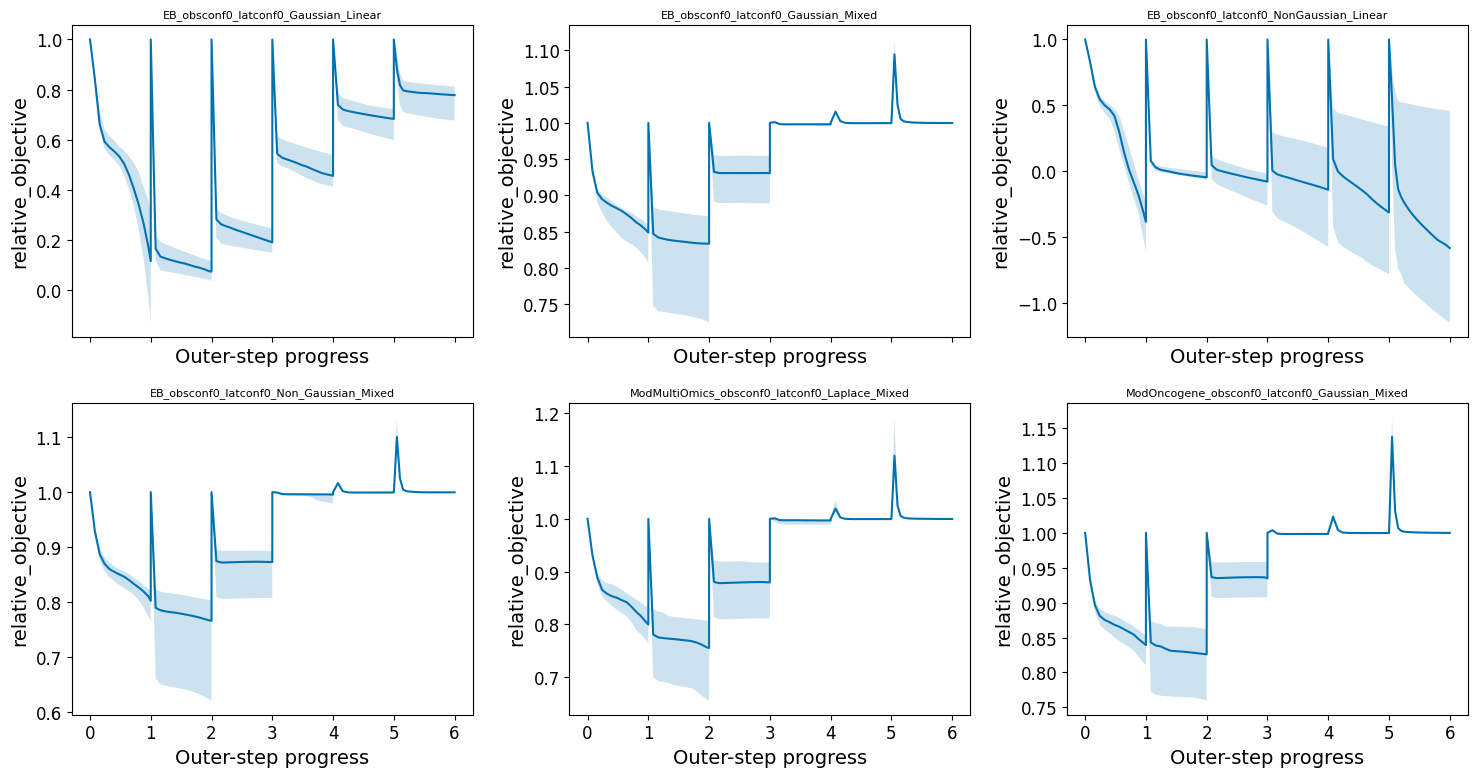

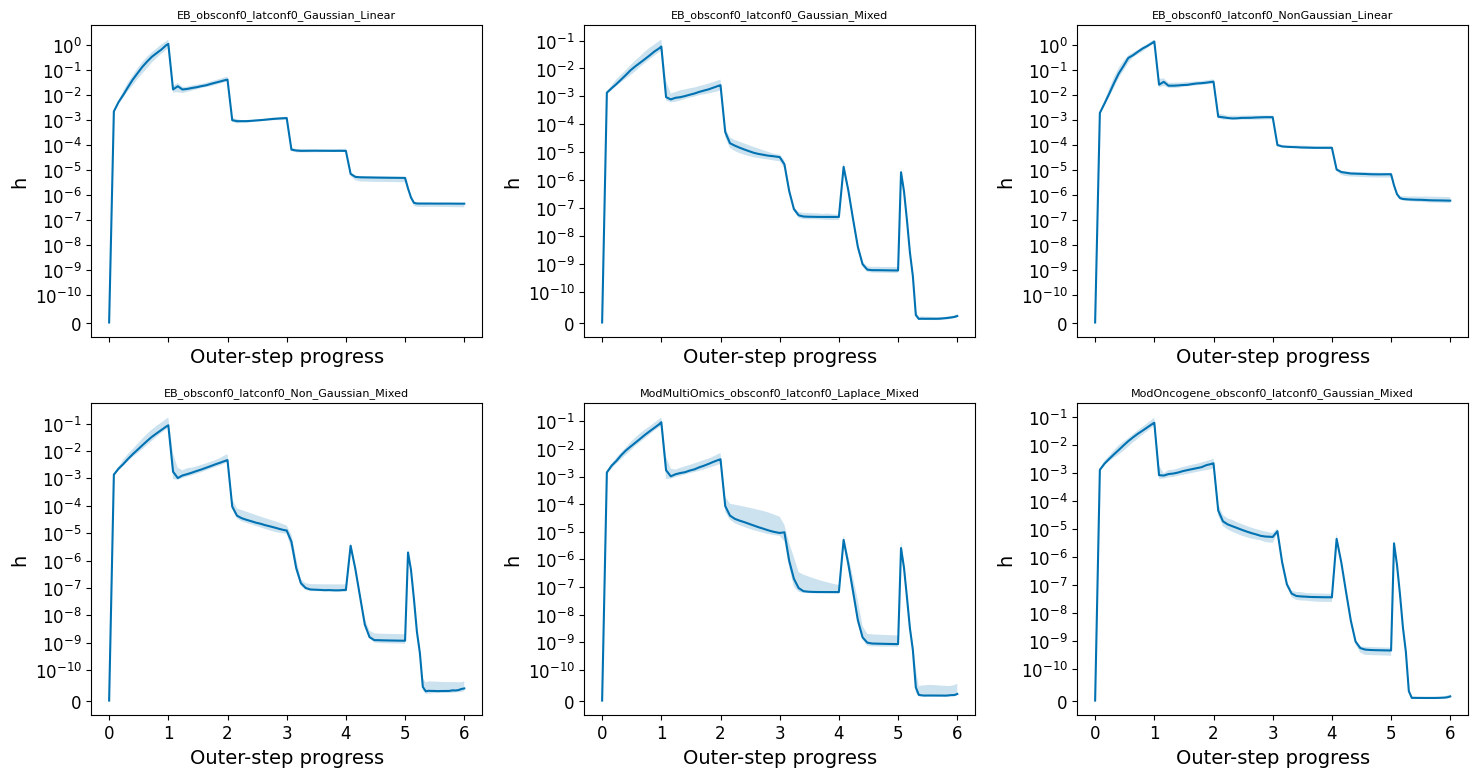

In [2]:
fits = []
points = []
for path in sorted((ROOT / "results/prism/convergence/fits").rglob("*.json")):
    p = json.loads(path.read_text())
    c = p.get("convergence") or {}
    identity = str(path.relative_to(ROOT))
    fits.append(
        dict(
            family=p["family"],
            dataset_seed=p["dataset_seed"],
            model_seed=p["model_seed"],
            status=p["status"],
            runtime_seconds=p.get("runtime_seconds"),
            last_step_h=c.get("last_step_h"),
            last_step_stop=c.get("last_step_stop"),
            retries=p.get("retries_h_negative", 0),
        )
    )
    for point in c.get("trace", []):
        points.append(dict(fit=identity, family=p["family"], **point))
traces = pd.DataFrame(points)
traces["start"] = traces.groupby(["fit", "outer_step", "attempt"]).objective.transform("first")
traces["relative_objective"] = traces.objective / traces.start
traces["progress"] = traces.outer_step + traces.iteration / traces.outer_step.map(
    lambda s: 5000 if s == 5 else 3125
)
# Quantiles are descriptive across fits, not independent dataset uncertainty.
summary = (
    traces.groupby(["family", "progress"])[["relative_objective", "h"]]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)
summary.columns = ["_".join(map(str, col)) for col in summary.columns]
summary = summary.reset_index()
display(summary.head(20))
for metric in ("relative_objective", "h"):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
    for ax, (family, g) in zip(axes.flat, summary.groupby("family")):
        ax.plot(g.progress, g[metric + "_0.5"])
        ax.fill_between(g.progress, g[metric + "_0.25"], g[metric + "_0.75"], alpha=0.2)
        ax.set(
            title=family.replace("20nodes_", ""), xlabel="Outer-step progress", ylabel=metric
        )
        ax.title.set_fontsize(8)
        if metric == "h":
            ax.set_yscale("symlog", linthresh=1e-10)
    fig.tight_layout()
    fig.savefig(th.OUTPUT / f"{metric}_all_families.pdf")
    display(fig)
    plt.close(fig)
